# Chapter 3: Subspaces and Orthogonality — Coding Lab (`proj.ipynb`)

**Mathematics for AI and Machine Learning** ([math4ai.org](https://math4ai.org))  
*Author: Henry Fuheng Wu*

This interactive notebook implements every theoretical result, algorithm, and exercise from **Chapter 3 (Subspaces and Orthogonality)** using **NumPy**, **PyTorch**, and **Matplotlib**:
1. **Part 1 — The Four Fundamental Subspaces & Gram–Schmidt Completion (Exercise 1)**: Extracting orthonormal bases for $C(X), N(X^\top), C(X^\top), N(X)$ via SVD, verifying integer bases & Rank–Nullity, and coding the constructive Gram–Schmidt completion algorithm for $N(A^\top)$.
2. **Part 2 — Regularization & Solution Space in Ridge Regression (Exercise 2)**: Singular $X^\top X$, eigenvalue shifts $+\lambda I$, and why $\hat{\boldsymbol\theta}_{\text{ridge}} \in C(X^\top) \perp N(X)$ eliminates null-space ambiguity.
3. **Part 3 — Rank & Model Capacity in Neural Networks (Exercise 3)**: Visualizing 3D-to-1D output collapse $C(W)$ and 2D invisible input planes $N(W)$ in a PyTorch linear layer.
4. **Part 4 — Orthonormal Initialization, Least-Squares Split & Woodbury Inverse (Exercises 4 & 5)**: Testing $Q^\top Q = I$, reflections vs. rotations ($\det Q = \pm 1$), 50-layer deep signal propagation, orthogonal decomposition $\mathbb{R}^M = C(X) \oplus N(X^\top)$, and the Woodbury regularized inverse.
5. **Part 5 — Complex Rotations & Rotary Position Embedding (RoPE) in PyTorch**: Unit-modulus eigenvalues $|\lambda| = 1$, production complex-number RoPE (`torch.view_as_complex`), exact shift invariance $(R_m\mathbf{q})^\top(R_n\mathbf{k}) = \mathbf{q}^\top R_{n-m}\mathbf{k}$, and Toeplitz attention heatmaps.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
torch.manual_seed(42)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
print(f"NumPy: {np.__version__} | PyTorch: {torch.__version__}")

NumPy: 2.4.6 | PyTorch: 2.10.0+cu128


---
## Part 1: The Four Fundamental Subspaces & Gram–Schmidt Completion (Exercise 1)

In **Exercise 1**, we analyze the linear regression design matrix with $N=2$ samples and $d=3$ features:
$$X = \begin{bmatrix} 1 & 2 & 3 \\ 2 & 4 & 6 \end{bmatrix} \in \mathbb{R}^{2 \times 3}, \qquad \operatorname{rank}(X) = r = 1.$$
- **Sample space $\mathbb{R}^2 = C(X) \oplus N(X^\top)$**: $C(X) = \operatorname{span}\{[1, 2]^\top\}$ ($\dim=1$) and $N(X^\top) = \operatorname{span}\{[-2, 1]^\top\}$ ($\dim=1$, encoding $\text{sample}_1 = 2\,\text{sample}_0$).
- **Feature space $\mathbb{R}^3 = C(X^\top) \oplus N(X)$**: $C(X^\top) = \operatorname{span}\{[1, 2, 3]^\top\}$ ($\dim=1$) and $N(X) = \operatorname{span}\{[-2, 1, 0]^\top, [-3, 0, 1]^\top\}$ ($\dim=2$, encoding $f_1 = 2f_0$ and $f_2 = 3f_0$).

In [2]:
# Exercise 1: Extracting all 4 fundamental subspaces via full SVD
X = np.array([[1., 2., 3.],
              [2., 4., 6.]])                 # shape (N=2, d=3)

U, s, Vt = np.linalg.svd(X, full_matrices=True)
r = int(np.sum(s > 1e-10))

C_X  = U[:, :r]      # Orthonormal basis of C(X)   in R^2 (dim r = 1)
N_XT = U[:, r:]      # Orthonormal basis of N(X^T) in R^2 (dim N - r = 1)
C_XT = Vt[:r].T      # Orthonormal basis of C(X^T) in R^3 (dim r = 1)
N_X  = Vt[r:].T      # Orthonormal basis of N(X)   in R^3 (dim d - r = 2)

print(f"Singular values of X: {s}")
print(f"Rank r = {r} | dims -> C(X): {C_X.shape[1]}, N(X^T): {N_XT.shape[1]}, C(X^T): {C_XT.shape[1]}, N(X): {N_X.shape[1]}")
print(f"Rank-Nullity on X:   dim C(X) + dim N(X)   = {C_X.shape[1]} + {N_X.shape[1]} = {X.shape[1]} (d)")
print(f"Rank-Nullity on X^T: dim C(X^T) + dim N(X^T) = {C_XT.shape[1]} + {N_XT.shape[1]} = {X.shape[0]} (N)\n")

# Verify analytical integer bases and orthogonal complement identities
V_null_int = np.array([[-2., -3.],
                       [ 1.,  0.],
                       [ 0.,  1.]])          # columns span N(X)
u_lnull_int = np.array([-2., 1.])            # spans N(X^T)

print("X @ V_null_int == 0:    ", np.allclose(X @ V_null_int, 0))
print("X.T @ u_lnull_int == 0: ", np.allclose(X.T @ u_lnull_int, 0))
print("C(X)   perp N(X^T):     ", np.allclose(C_X.T @ N_XT, 0))
print("C(X^T) perp N(X):       ", np.allclose(C_XT.T @ N_X, 0))
print("P_{C(X)} + P_{N(X^T)} == I_2:", np.allclose(C_X @ C_X.T + N_XT @ N_XT.T, np.eye(2)))
print("P_{C(X^T)} + P_{N(X)} == I_3:", np.allclose(C_XT @ C_XT.T + N_X @ N_X.T, np.eye(3)))

Singular values of X: [8.3666 0.    ]
Rank r = 1 | dims -> C(X): 1, N(X^T): 1, C(X^T): 1, N(X): 2
Rank-Nullity on X:   dim C(X) + dim N(X)   = 1 + 2 = 3 (d)
Rank-Nullity on X^T: dim C(X^T) + dim N(X^T) = 1 + 1 = 2 (N)

X @ V_null_int == 0:     True
X.T @ u_lnull_int == 0:  True
C(X)   perp N(X^T):      True
C(X^T) perp N(X):        True
P_{C(X)} + P_{N(X^T)} == I_2: True
P_{C(X^T)} + P_{N(X)} == I_3: True


Gram-Schmidt N(X^T) basis vector: [ 0.8944 -0.4472]
Orthogonal to C(X): True


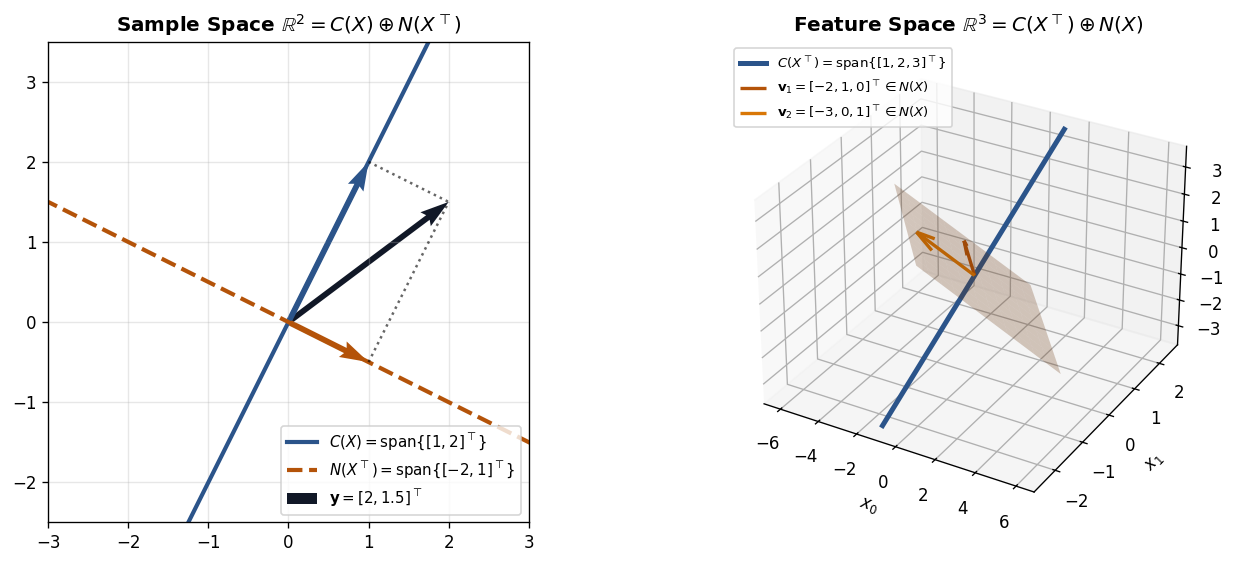

In [3]:
# Constructive Gram-Schmidt Completion for N(A^T) + Visualizing the 4 Subspaces
def gram_schmidt_left_null(A, tol=1e-10):
    M, _ = A.shape
    U_svd, s_svd, _ = np.linalg.svd(A, full_matrices=False)
    r_rank = int(np.sum(s_svd > tol))
    Q = [U_svd[:, i] for i in range(r_rank)]
    for m in range(M):
        v = np.eye(M)[:, m].copy()
        for q in Q:
            v = v - (v @ q) * q
        if np.linalg.norm(v) > tol:
            Q.append(v / np.linalg.norm(v))
            if len(Q) == M:
                break
    return np.column_stack(Q[:r_rank]), np.column_stack(Q[r_rank:])

Q_col_gs, Q_lnull_gs = gram_schmidt_left_null(X)
print("Gram-Schmidt N(X^T) basis vector:", Q_lnull_gs.ravel())
print("Orthogonal to C(X):", np.allclose(X.T @ Q_lnull_gs, 0))

fig = plt.figure(figsize=(12, 4.8))

# Left panel: Sample space R^2 = C(X) (+) N(X^T)
ax1 = fig.add_subplot(1, 2, 1)
t = np.linspace(-2.5, 2.5, 100)
ax1.plot(t * 1, t * 2, color="#2b548a", lw=2.5, label=r"$C(X) = \mathrm{span}\{[1, 2]^\top\}$")
ax1.plot(t * (-2), t * 1, color="#b45309", lw=2.5, ls="--", label=r"$N(X^\top) = \mathrm{span}\{[-2, 1]^\top\}$")
y_demo = np.array([2.0, 1.5])
y_proj = (C_X @ C_X.T) @ y_demo
y_rej  = (N_XT @ N_XT.T) @ y_demo
ax1.quiver(0, 0, y_demo[0], y_demo[1], angles="xy", scale_units="xy", scale=1, color="#111827", width=0.012, label=r"$\mathbf{y} = [2, 1.5]^\top$")
ax1.quiver(0, 0, y_proj[0], y_proj[1], angles="xy", scale_units="xy", scale=1, color="#2b548a", width=0.012)
ax1.quiver(0, 0, y_rej[0], y_rej[1], angles="xy", scale_units="xy", scale=1, color="#b45309", width=0.012)
ax1.plot([y_proj[0], y_demo[0]], [y_proj[1], y_demo[1]], "k:", alpha=0.6)
ax1.plot([y_rej[0], y_demo[0]], [y_rej[1], y_demo[1]], "k:", alpha=0.6)
ax1.set_xlim(-3, 3); ax1.set_ylim(-2.5, 3.5); ax1.set_aspect("equal")
ax1.grid(True, alpha=0.3)
ax1.set_title(r"Sample Space $\mathbb{R}^2 = C(X) \oplus N(X^\top)$", fontweight="bold")
ax1.legend(loc="lower right", fontsize=9)

# Right panel: Feature space R^3 = C(X^T) (+) N(X)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
g1, g2 = np.meshgrid(np.linspace(-1.2, 1.2, 12), np.linspace(-1.2, 1.2, 12))
# Plane x0 + 2*x1 + 3*x2 = 0 => x0 = -2*x1 - 3*x2
g0 = -2 * g1 - 3 * g2
ax2.plot_surface(g0, g1, g2, color="#b45309", alpha=0.25)
s_line = np.linspace(-1.2, 1.2, 50)
ax2.plot(s_line * 1, s_line * 2, s_line * 3, color="#2b548a", lw=3, label=r"$C(X^\top) = \mathrm{span}\{[1,2,3]^\top\}$")
ax2.quiver(0, 0, 0, -2, 1, 0, color="#b45309", lw=2, label=r"$\mathbf{v}_1 = [-2,1,0]^\top \in N(X)$")
ax2.quiver(0, 0, 0, -3, 0, 1, color="#d97706", lw=2, label=r"$\mathbf{v}_2 = [-3,0,1]^\top \in N(X)$")
ax2.set_xlabel("$x_0$"); ax2.set_ylabel("$x_1$"); ax2.set_zlabel("$x_2$")
ax2.set_title(r"Feature Space $\mathbb{R}^3 = C(X^\top) \oplus N(X)$", fontweight="bold")
ax2.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

---
## Part 2: Regularization & Solution Space in Ridge Regression (Exercise 2)

In **Exercise 2**, we compare unregularized normal equations $X^\top X \boldsymbol\theta = X^\top \mathbf{y}$ against Ridge regression $(X^\top X + \lambda I)\boldsymbol\theta = X^\top \mathbf{y}$ ($\lambda > 0$):
1. $X^\top X$ has rank $1 < 3$ (eigenvalues $\{0, 0, 70\}$), so any $\mathbf{v} \in N(X)$ satisfies $X^\top X \mathbf{v} = \mathbf{0}$.
2. Adding $\lambda I$ shifts the eigenvalues to $\{\lambda, \lambda, 70+\lambda\} > 0$, making $X^\top X + \lambda I$ strictly positive definite.
3. Decomposing $\boldsymbol\theta = \boldsymbol\theta_{\text{row}} + \boldsymbol\theta_{\text{null}}$ with $\boldsymbol\theta_{\text{row}} \in C(X^\top) \perp N(X)$, the Ridge objective separates as:
$$\|X\boldsymbol\theta_{\text{row}} - \mathbf{y}\|_2^2 + \lambda\|\boldsymbol\theta_{\text{row}}\|_2^2 + \lambda\|\boldsymbol\theta_{\text{null}}\|_2^2,$$
which strictly forces $\hat{\boldsymbol\theta}_{\text{null}} = \mathbf{0}$, so $\hat{\boldsymbol\theta}_{\text{ridge}} \in C(X^\top)$ for every $\lambda > 0$!

X^T X:
 [[ 5. 10. 15.]
 [10. 20. 30.]
 [15. 30. 45.]]
rank(X^T X):           1
eigvals(X^T X):        [-0.  0. 70.]
X^T X @ V_null == 0:   True
lambda=10.0000 -> theta_ridge=[0.875 1.75  2.625] | ||V_null^T theta||=1.33e-15
lambda=2.0000 -> theta_ridge=[0.9722 1.9444 2.9167] | ||V_null^T theta||=1.02e-14
lambda=0.1000 -> theta_ridge=[0.9986 1.9971 2.9957] | ||V_null^T theta||=2.62e-13
lambda=0.0001 -> theta_ridge=[1. 2. 3.] | ||V_null^T theta||=3.38e-10

Minimum-norm solution X^+ y in C(X^T): [1. 2. 3.] (||theta||_2 = 3.7417)


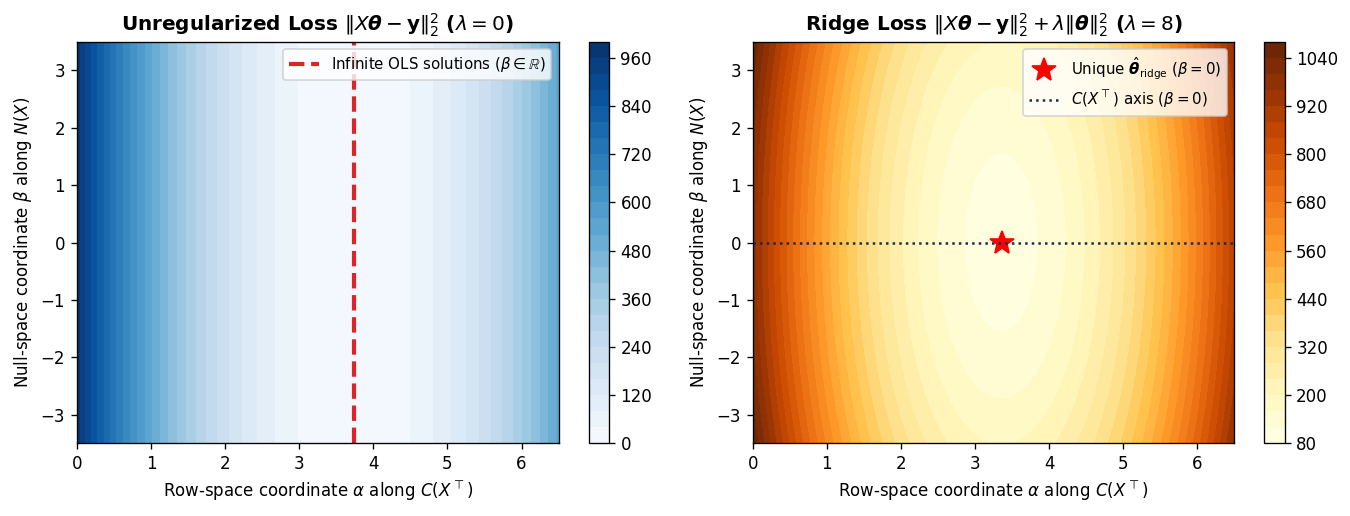

In [4]:
# Exercise 2: Ridge solution space and null-space elimination
y_reg = np.array([14., 28.])                 # exact target y = X @ [1, 2, 3]^T
XtX = X.T @ X

print("X^T X:\n", XtX)
print("rank(X^T X):          ", np.linalg.matrix_rank(XtX))
print("eigvals(X^T X):       ", np.round(np.linalg.eigvalsh(XtX), 4))
print("X^T X @ V_null == 0:  ", np.allclose(XtX @ V_null_int, 0))

for lam in [10.0, 2.0, 0.1, 1e-4]:
    theta_lam = np.linalg.solve(XtX + lam * np.eye(3), X.T @ y_reg)
    null_proj = np.linalg.norm(V_null_int.T @ theta_lam)
    print(f"lambda={lam:6.4f} -> theta_ridge={np.round(theta_lam, 4)} | ||V_null^T theta||={null_proj:.2e}")

theta_pinv = np.linalg.pinv(X) @ y_reg
print(f"\nMinimum-norm solution X^+ y in C(X^T): {theta_pinv} (||theta||_2 = {np.linalg.norm(theta_pinv):.4f})")

# Visualize OLS flat valley vs Ridge unique minimum across C(X^T) x N(X)
u_row = np.array([1., 2., 3.]) / np.sqrt(14.0)      # unit vector in C(X^T)
v_nul = np.array([-2., 1., 0.]) / np.sqrt(5.0)      # unit vector in N(X)
alphas = np.linspace(0.0, 6.5, 120)
betas  = np.linspace(-3.5, 3.5, 120)
A_grid, B_grid = np.meshgrid(alphas, betas)

# Since X(alpha*u_row + beta*v_nul) = alpha * X u_row, data loss depends ONLY on alpha!
Xu = X @ u_row
ols_loss = (A_grid * Xu[0] - y_reg[0])**2 + (A_grid * Xu[1] - y_reg[1])**2
lam_vis = 8.0
ridge_loss = ols_loss + lam_vis * (A_grid**2 + B_grid**2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4))
cs1 = ax1.contourf(A_grid, B_grid, ols_loss, levels=25, cmap="Blues")
ax1.axvline(np.sqrt(14.0), color="#dc2626", lw=2.5, ls="--", label=r"Infinite OLS solutions ($\beta \in \mathbb{R}$)")
ax1.set_xlabel(r"Row-space coordinate $\alpha$ along $C(X^\top)$")
ax1.set_ylabel(r"Null-space coordinate $\beta$ along $N(X)$")
ax1.set_title(r"Unregularized Loss $\|X\boldsymbol{\theta} - \mathbf{y}\|_2^2$ ($\lambda = 0$)", fontweight="bold")
ax1.legend(loc="upper right", fontsize=9)
plt.colorbar(cs1, ax=ax1)

cs2 = ax2.contourf(A_grid, B_grid, ridge_loss, levels=25, cmap="YlOrBr")
alpha_opt = (70.0 / (70.0 + lam_vis)) * np.sqrt(14.0)
ax2.plot(alpha_opt, 0.0, "r*", markersize=15, label=r"Unique $\hat{\boldsymbol{\theta}}_{\mathrm{ridge}}$ ($\beta = 0$)")
ax2.axhline(0.0, color="#162d50", lw=1.5, ls=":", label=r"$C(X^\top)$ axis ($\beta = 0$)")
ax2.set_xlabel(r"Row-space coordinate $\alpha$ along $C(X^\top)$")
ax2.set_ylabel(r"Null-space coordinate $\beta$ along $N(X)$")
ax2.set_title(r"Ridge Loss $\|X\boldsymbol{\theta} - \mathbf{y}\|_2^2 + \lambda\|\boldsymbol{\theta}\|_2^2$ ($\lambda = 8$)", fontweight="bold")
ax2.legend(loc="upper right", fontsize=9)
plt.colorbar(cs2, ax=ax2)
plt.tight_layout()
plt.show()

---
## Part 3: Rank & Model Capacity in Neural Networks (Exercise 3)

In **Exercise 3**, we examine a 3-neuron linear layer $f(\mathbf{x}) = W\mathbf{x}$ with weight matrix:
$$W = \begin{bmatrix} 1 & 2 & 3 \\ 2 & 4 & 6 \\ 0 & 0 & 0 \end{bmatrix} \in \mathbb{R}^{3 \times 3}, \qquad \operatorname{rank}(W) = 1.$$
Even though the output lives in $\mathbb{R}^3$, every output vector collapses onto the 1D line $C(W) = \operatorname{span}\{[1, 2, 0]^\top\}$, while any perturbation $\boldsymbol\delta \in N(W) = \operatorname{span}\{[-2, 1, 0]^\top, [-3, 0, 1]^\top\}$ produces zero change in layer output.

Input cloud shape & rank:  (300, 3) -> rank = 3
Output cloud shape & rank: (300, 3) -> rank = 1
||delta_null||_2:           4.7434
||f(x + delta_null) - f(x)||: 0.0


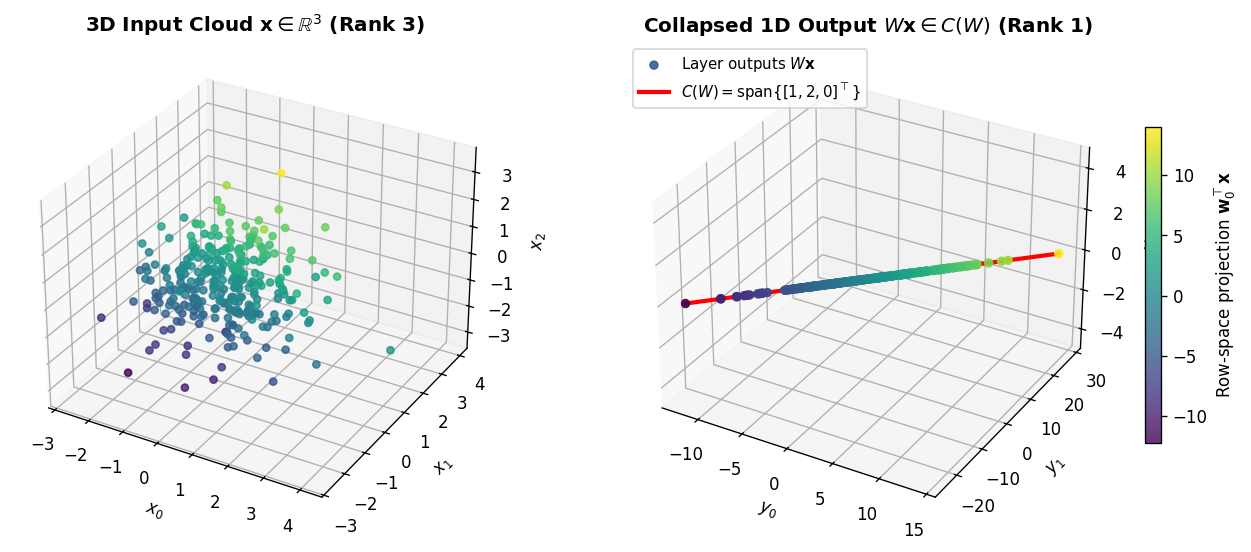

In [5]:
# Exercise 3: PyTorch Linear Layer Bottleneck & 3D Visualization
W_torch = torch.tensor([[1., 2., 3.],
                        [2., 4., 6.],
                        [0., 0., 0.]])
layer = torch.nn.Linear(3, 3, bias=False)
with torch.no_grad():
    layer.weight.copy_(W_torch)

torch.manual_seed(0)
X_cloud = torch.randn(300, 3)
Y_cloud = layer(X_cloud)

print("Input cloud shape & rank: ", tuple(X_cloud.shape), "-> rank =", torch.linalg.matrix_rank(X_cloud).item())
print("Output cloud shape & rank:", tuple(Y_cloud.shape), "-> rank =", torch.linalg.matrix_rank(Y_cloud).item())

# Verify invisibility of N(W) perturbations
x_sample = torch.tensor([1.0, -0.5, 2.0])
delta_null = 4.0 * torch.tensor([-2., 1., 0.]) - 2.5 * torch.tensor([-3., 0., 1.])
print("||delta_null||_2:          ", round(delta_null.norm().item(), 4))
print("||f(x + delta_null) - f(x)||:", (layer(x_sample + delta_null) - layer(x_sample)).norm().item())

# 3D visualization: Input 3D sphere vs Collapsed 1D line in output space
X_np = X_cloud.numpy()
Y_np = Y_cloud.detach().numpy()
row_coord = X_np @ np.array([1., 2., 3.])

fig = plt.figure(figsize=(11.5, 4.6))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
sc1 = ax1.scatter(X_np[:, 0], X_np[:, 1], X_np[:, 2], c=row_coord, cmap="viridis", s=18, alpha=0.8)
ax1.set_title("3D Input Cloud $\\mathbf{x} \\in \\mathbb{R}^3$ (Rank 3)", fontweight="bold")
ax1.set_xlabel("$x_0$"); ax1.set_ylabel("$x_1$"); ax1.set_zlabel("$x_2$")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(Y_np[:, 0], Y_np[:, 1], Y_np[:, 2], c=row_coord, cmap="viridis", s=22, alpha=0.9, label="Layer outputs $W\\mathbf{x}$")
line_t = np.linspace(row_coord.min(), row_coord.max(), 50)
ax2.plot(line_t * 1, line_t * 2, line_t * 0, "r-", lw=2.5, label=r"$C(W) = \mathrm{span}\{[1, 2, 0]^\top\}$")
ax2.set_title("Collapsed 1D Output $W\\mathbf{x} \\in C(W)$ (Rank 1)", fontweight="bold")
ax2.set_xlabel("$y_0$"); ax2.set_ylabel("$y_1$"); ax2.set_zlabel("$y_2$")
ax2.set_zlim(-5, 5)
ax2.legend(loc="upper left", fontsize=9)
plt.colorbar(sc1, ax=ax2, shrink=0.65, label=r"Row-space projection $\mathbf{w}_0^\top\mathbf{x}$")
plt.tight_layout()
plt.show()

---
## Part 4: Orthonormal Initialization, Least-Squares Split & Woodbury Inverse (Exercises 4 & 5)

- **Exercise 4**: Test $Q_1, Q_2, Q_3$ for $Q^\top Q = I$ and length preservation $\|Q\mathbf{x}\|_2 = \|\mathbf{x}\|_2$ on $\mathbf{x} = [1, 1]^\top$, and compare 50-layer signal propagation under orthogonal vs. Gaussian initialization.
- **Exercise 5**: For column-orthonormal $X = \frac{1}{\sqrt{2}}\begin{bmatrix} 1 & 1 \\ 1 & -1 \\ 0 & 0 \end{bmatrix}$ and $\mathbf{y} = [1, 1, 1]^\top$, verify $X^\top X = I_2$, $P = XX^\top = \operatorname{diag}(1, 1, 0) \ne I_3$, $\mathbf{y} = \hat{\mathbf{y}} + \mathbf{r} \in C(X) \oplus N(X^\top)$, and the Woodbury regularized inverse:
$$(XX^\top + \lambda I_M)^{-1} = \frac{1}{\lambda}I_M - \frac{1}{\lambda(1+\lambda)}XX^\top.$$

In [6]:
# Exercise 4: Testing Q1, Q2, Q3 and 50-layer signal propagation
Q1 = np.array([[1., 1.], [1., -1.]]) / np.sqrt(2)
Q2 = np.array([[1., 0.], [0., 1.], [1., 0.]])
Q3 = np.array([[3/5, 4/5], [-4/5, 3/5]])
x_test = np.array([1., 1.])

for name, Q in [("Q1", Q1), ("Q2", Q2), ("Q3", Q3)]:
    qtq = Q.T @ Q
    is_orth = np.allclose(qtq, np.eye(Q.shape[1]))
    det_val = f"{np.linalg.det(Q):+.1f}" if Q.shape[0] == Q.shape[1] else "N/A"
    print(f"{name}: Q^T Q == I -> {str(is_orth):5s} | det = {det_val:4s} | ||Qx||_2 = {np.linalg.norm(Q @ x_test):.4f} (||x||_2 = {np.linalg.norm(x_test):.4f})")

# 50-layer propagation: Orthogonal vs slightly mis-scaled Gaussian
torch.manual_seed(42)
d_dim, num_layers = 64, 50
h_orth = torch.randn(1, d_dim)
h_over = h_orth.clone()
h_under = h_orth.clone()
norms_orth, norms_over, norms_under = [h_orth.norm().item()], [h_over.norm().item()], [h_under.norm().item()]

for _ in range(num_layers):
    W_o = torch.empty(d_dim, d_dim)
    torch.nn.init.orthogonal_(W_o)
    W_g = torch.randn(d_dim, d_dim) / np.sqrt(d_dim)
    h_orth  = h_orth @ W_o.T
    h_over  = h_over @ (1.10 * W_g).T
    h_under = h_under @ (0.90 * W_g).T
    norms_orth.append(h_orth.norm().item())
    norms_over.append(h_over.norm().item())
    norms_under.append(h_under.norm().item())

print(f"\nNorm at layer 0: {norms_orth[0]:.4f} -> Norm at layer 50 (Orthogonal): {norms_orth[-1]:.4f}")

Q1: Q^T Q == I -> True  | det = -1.0 | ||Qx||_2 = 1.4142 (||x||_2 = 1.4142)
Q2: Q^T Q == I -> False | det = N/A  | ||Qx||_2 = 1.7321 (||x||_2 = 1.4142)
Q3: Q^T Q == I -> True  | det = +1.0 | ||Qx||_2 = 1.4142 (||x||_2 = 1.4142)

Norm at layer 0: 8.3975 -> Norm at layer 50 (Orthogonal): 8.3975


In [7]:
# Exercise 5: Orthonormal projection split y = y_hat + r and Woodbury Regularized Inverse
X5 = np.array([[1.,  1.],
               [1., -1.],
               [0.,  0.]]) / np.sqrt(2)
y5 = np.array([1., 1., 1.])

P5 = X5 @ X5.T
y5_hat = P5 @ y5
r5 = y5 - y5_hat

print("X5^T @ X5 == I_2:       ", np.allclose(X5.T @ X5, np.eye(2)))
print("P5 = X5 @ X5^T:\n", P5)
print("P5^2 == P5 (idempotent):", np.allclose(P5 @ P5, P5))
print("y_hat in C(X5):         ", y5_hat)
print("r in N(X5^T):           ", r5)
print("X5^T @ r == 0:          ", np.allclose(X5.T @ r5, 0))
print("y_hat . r == 0:         ", np.isclose(y5_hat @ r5, 0))

# Woodbury regularized inverse verification
lam5 = 0.5
inv_exact = np.linalg.inv(P5 + lam5 * np.eye(3))
inv_wood  = np.eye(3) / lam5 - P5 / (lam5 * (1.0 + lam5))
print("Woodbury matches exact inverse:", np.allclose(inv_exact, inv_wood))

X5^T @ X5 == I_2:        True
P5 = X5 @ X5^T:
 [[ 1. -0.  0.]
 [-0.  1.  0.]
 [ 0.  0.  0.]]
P5^2 == P5 (idempotent): True
y_hat in C(X5):          [1. 1. 0.]
r in N(X5^T):            [0. 0. 1.]
X5^T @ r == 0:           True
y_hat . r == 0:          True
Woodbury matches exact inverse: True


---
## Part 5: Complex Rotations & Rotary Position Embedding (RoPE) in PyTorch

Chapter 3 shows that a 2D rotation matrix $R(\theta) = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix}$ has complex eigenvalues $e^{\pm i\theta}$ of unit modulus ($|\lambda| = 1$) and corresponds to complex multiplication $(x + iy)e^{i\theta}$.

**Rotary Position Embedding (RoPE)** applies this to every pair of query/key coordinates at token position $m$ with frequency $\theta_i = 10000^{-2i/d}$, giving:
1. **Exact norm preservation**: $\|R_m \mathbf{q}\|_2 = \|\mathbf{q}\|_2$.
2. **Relative-position shift invariance**: $(R_m \mathbf{q})^\top (R_n \mathbf{k}) = \mathbf{q}^\top R_{n-m} \mathbf{k}$, so the attention matrix across positions $(m, n)$ is **Toeplitz** (constant along diagonals $m - n = \text{const}$)!

In [8]:
# Complex eigenvalues of 2D rotation + PyTorch Complex-Number RoPE Implementation
theta_demo = 0.6
R_2d = np.array([[np.cos(theta_demo), -np.sin(theta_demo)],
                 [np.sin(theta_demo),  np.cos(theta_demo)]])
eigvals_R = np.linalg.eigvals(R_2d)
print("Eigenvalues of R(0.6):", np.round(eigvals_R, 4))
print("Moduli |lambda|:      ", np.round(np.abs(eigvals_R), 6))

def apply_rope_torch(x: torch.Tensor, pos: torch.Tensor, base: float = 10000.0) -> torch.Tensor:
    """Rotate 2D coordinate pairs of x (..., d) by position angles pos * theta_i via complex multiplication."""
    d = x.shape[-1]
    theta = base ** (-torch.arange(0, d, 2, dtype=torch.float32) / d)
    angles = pos.float().unsqueeze(-1) * theta                      # (..., d/2)
    x_complex = torch.view_as_complex(x.float().reshape(*x.shape[:-1], d // 2, 2))
    rotors = torch.polar(torch.ones_like(angles), angles)           # e^{i m theta_i}
    return torch.view_as_real(x_complex * rotors).flatten(-2)

torch.manual_seed(7)
q_vec = torch.randn(32)
k_vec = torch.randn(32)

q_rot_19 = apply_rope_torch(q_vec, torch.tensor(19))
print(f"\n||q||_2 = {q_vec.norm().item():.6f} vs ||R_19 q||_2 = {q_rot_19.norm().item():.6f}")

# Shift invariance check: (m, n) = (15, 8) vs (207, 200) -> both have relative distance m - n = 7
score_15_8    = apply_rope_torch(q_vec, torch.tensor(15))  @ apply_rope_torch(k_vec, torch.tensor(8))
score_207_200 = apply_rope_torch(q_vec, torch.tensor(207)) @ apply_rope_torch(k_vec, torch.tensor(200))
print(f"RoPE score at (15, 8):    {score_15_8.item():.6f}")
print(f"RoPE score at (207, 200): {score_207_200.item():.6f} (exact match: {torch.allclose(score_15_8, score_207_200, atol=1e-5)})")

Eigenvalues of R(0.6): [0.8253+0.5646j 0.8253-0.5646j]
Moduli |lambda|:       [1. 1.]

||q||_2 = 5.554375 vs ||R_19 q||_2 = 5.554375
RoPE score at (15, 8):    -5.086051
RoPE score at (207, 200): -5.086040 (exact match: True)


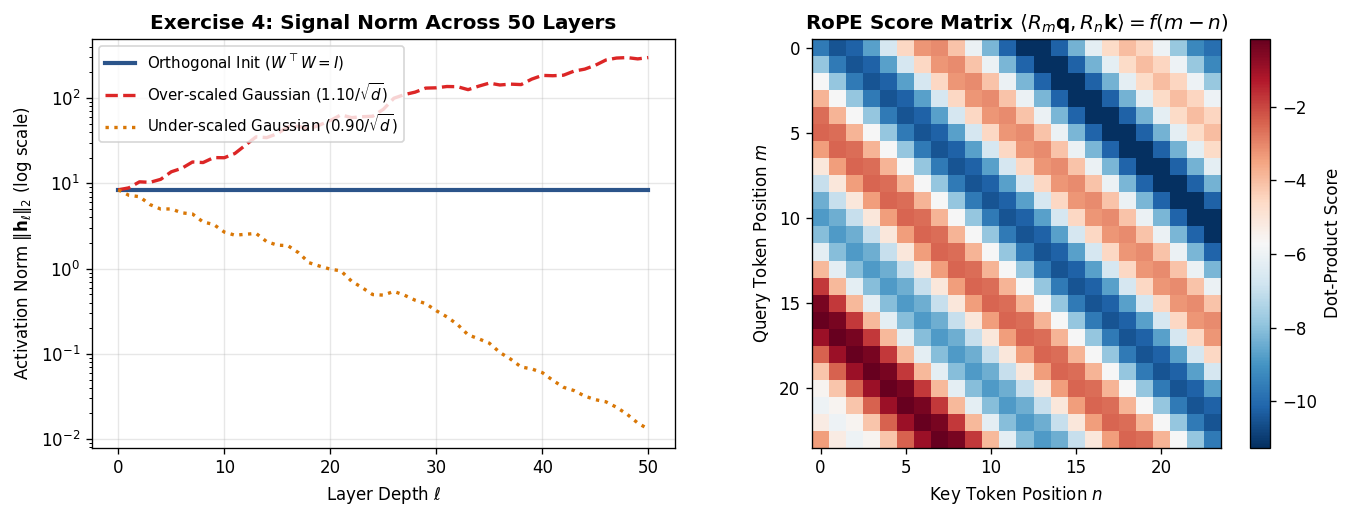

In [9]:
# Visualizing (1) Deep Orthogonal vs Gaussian Norm Propagation & (2) Toeplitz RoPE Attention Heatmap
positions = torch.arange(24)
Q_seq = apply_rope_torch(q_vec.unsqueeze(0).expand(24, -1), positions)   # (24, 32)
K_seq = apply_rope_torch(k_vec.unsqueeze(0).expand(24, -1), positions)   # (24, 32)
S_rope = (Q_seq @ K_seq.T).numpy()                                       # (24, 24) Toeplitz matrix!

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4))

# Panel 1: 50-Layer Signal Propagation (Exercise 4)
layers_idx = np.arange(num_layers + 1)
ax1.plot(layers_idx, norms_orth, color="#2b548a", lw=2.5, label=r"Orthogonal Init ($W^\top W = I$)")
ax1.plot(layers_idx, norms_over, color="#dc2626", lw=2, ls="--", label=r"Over-scaled Gaussian ($1.10 / \sqrt{d}$)")
ax1.plot(layers_idx, norms_under, color="#d97706", lw=2, ls=":", label=r"Under-scaled Gaussian ($0.90 / \sqrt{d}$)")
ax1.set_yscale("log")
ax1.set_xlabel("Layer Depth $\\ell$")
ax1.set_ylabel(r"Activation Norm $\|\mathbf{h}_\ell\|_2$ (log scale)")
ax1.set_title("Exercise 4: Signal Norm Across 50 Layers", fontweight="bold")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left", fontsize=9)

# Panel 2: Toeplitz RoPE Attention Score Matrix S_{m,n} = <R_m q, R_n k>
im = ax2.imshow(S_rope, cmap="RdBu_r", origin="upper")
ax2.set_xlabel("Key Token Position $n$")
ax2.set_ylabel("Query Token Position $m$")
ax2.set_title(r"RoPE Score Matrix $\langle R_m\mathbf{q}, R_n\mathbf{k}\rangle = f(m - n)$", fontweight="bold")
plt.colorbar(im, ax=ax2, label="Dot-Product Score")
plt.tight_layout()
plt.show()

---
## Summary & Alignment with Chapter 3

| Topic / Exercise | Mathematical Identity | AI / ML Takeaway |
|---|---|---|
| **Ex 1: Four Subspaces** | $\mathbb{R}^M = C(X) \oplus N(X^\top)$, $\mathbb{R}^N = C(X^\top) \oplus N(X)$ | $N(X)$ encodes redundant features; $N(X^\top)$ encodes redundant samples & residuals |
| **Ex 2: Ridge Solution Space** | $\hat{\boldsymbol\theta}_{\text{ridge}} = (X^\top X + \lambda I)^{-1}X^\top\mathbf{y} \in C(X^\top) \perp N(X)$ | $+\lambda I$ lifts zero eigenvalues and eliminates null-space parameter drift |
| **Ex 3: Layer Capacity** | $\dim C(W) = \operatorname{rank}(W)$, $\dim N(W) = d_{\text{in}} - \operatorname{rank}(W)$ | Low-rank layers collapse output dimensions and create a null-space blind spot |
| **Ex 4: Orthonormal Init** | $Q^\top Q = I \implies \|Q\mathbf{x}\|_2 = \|\mathbf{x}\|_2$, $\det Q = \pm 1$ | Orthogonal weight init preserves activation and gradient norms across deep layers |
| **Ex 5: Projection & Woodbury** | $\mathbf{y} = XX^\top\mathbf{y} + (I - XX^\top)\mathbf{y}$, $(XX^\top + \lambda I)^{-1} = \frac{1}{\lambda}I - \frac{1}{\lambda(1+\lambda)}XX^\top$ | Least squares is an orthogonal split into $C(X) \oplus N(X^\top)$ |
| **RoPE in LLMs** | $(R_m\mathbf{q})^\top(R_n\mathbf{k}) = \mathbf{q}^\top R_{n-m}\mathbf{k}$, $\|R_m\mathbf{q}\|_2 = \|\mathbf{q}\|_2$ | Block-diagonal 2D rotations encode exact relative token distance without altering norms |